# MASF: Lorenz96 with cubic measurements

Pretrain the score model from scratch, then run filtering with online fine-tuning. Figures are saved to `outputs/lorenz96/`.

In [1]:
import os, sys, glob
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, display
from huggingface_hub import snapshot_download

REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
OUT = "outputs/lorenz96"
os.makedirs(f"{OUT}/ckpt", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data

The 1000 Lorenz96 states at step 25 are downloaded from the Hugging Face dataset repo into `datasets/`.

In [2]:
snapshot_download("eunbii1/masf", repo_type="dataset", local_dir=REPO, allow_patterns="datasets/lorenz96/*")

In [3]:
from utils.run_utils import load_yaml, set_seed, measurement_update, time_update
from utils.build import build_steps, build_dynamics, build_measurement, build_method, build_dataset, build_pretraining_dataset, build_model, build_dataloader
from utils.summary import finalize_and_save
from methods.nonlinear_ours import predict

cfg = load_yaml(f"{REPO}/configs/lorenz96/cubic.yaml")
cfg["system"]["device"] = device
set_seed(cfg)

steps, total_step = build_steps(cfg)
dynamics, measurement, method = build_dynamics(cfg), build_measurement(cfg), build_method(cfg)
prior, truth, total_obs, obs = build_dataset(cfg, dynamics, measurement, steps)

[DATASET] prior (100, 1, 40) trajectory (101, 1, 40) dir ../datasets/lorenz96/dim40_num_samples1000


## Training

The forward process moves a state $x_0$ toward its measurement $H(x_0)$. The model predicts both $x_0$ and $H(x_0)$ from $x_t$.

In [4]:
def train(model, data, opt_cfg, epochs):
    measurement.update_stats(data)
    loader, _ = build_dataloader(measurement.norm.norm(data), opt_cfg["batch_size"], float(opt_cfg["val_ratio"]))
    opt = torch.optim.AdamW(model.parameters(), lr=float(opt_cfg["lr"]), weight_decay=opt_cfg["weight_decay"], betas=tuple(opt_cfg["betas"]))
    losses = []
    model.train()
    for _ in range(epochs):
        total = 0.0
        for (x0,) in loader:
            t = torch.rand(len(x0), device=device)
            xt, _ = measurement.forward_process(x0, t)
            x_hat, h_hat = predict(model, measurement, xt, t, cfg["method"]["target"])
            loss = F.mse_loss(x_hat, x0) + F.mse_loss(h_hat, measurement.H(x0))
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item()
        losses.append(total / len(loader))
    return losses

### Pretraining on 1000 simulated states

[DATASET for pretraining] prior (1000, 1, 40) dir ../datasets/lorenz96/dim40_num_samples1000


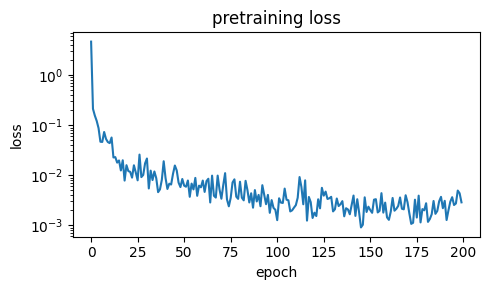

In [5]:
model = build_model(cfg)
pre_losses = train(model, build_pretraining_dataset(cfg, dynamics, steps), cfg["pretrain"], cfg["pretrain"]["epoch"])

plt.figure(figsize=(5, 3))
plt.semilogy(pre_losses)
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("pretraining loss")
plt.tight_layout()
plt.savefig(f"{OUT}/pretrain_loss.png", dpi=150)
plt.show()

## Filtering

At each measurement step: fine-tune on the current prior ensemble, sample the posterior, then propagate it with the dynamics.

In [6]:
tr = cfg["train"]
states = torch.empty((len(truth), *prior.shape), device=device)
for k, i in enumerate(steps):
    train(model, prior, tr, tr["online"]["full_epoch"])
    posterior = measurement_update(method, cfg, model, measurement, i, total_step, prior, obs, device)
    prior, states = time_update(dynamics, posterior, k, steps, total_step, states)

rmse, _ = finalize_and_save(cfg, OUT, dynamics, truth, obs, total_obs, states, steps, total_step)
print("RMSE", rmse)

RMSE 0.08496897330750675 FCRPS 0.04626643181387318 SSR 0.9874050019607464
RMSE 0.08496897330750675


## Results

Ground truth, posterior mean and measurement over time, then 1D profiles at the first, middle and last step, and the RMSE curve.

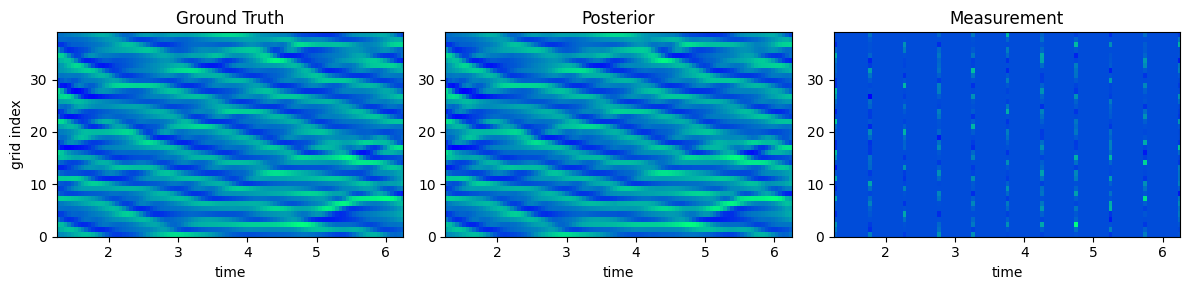

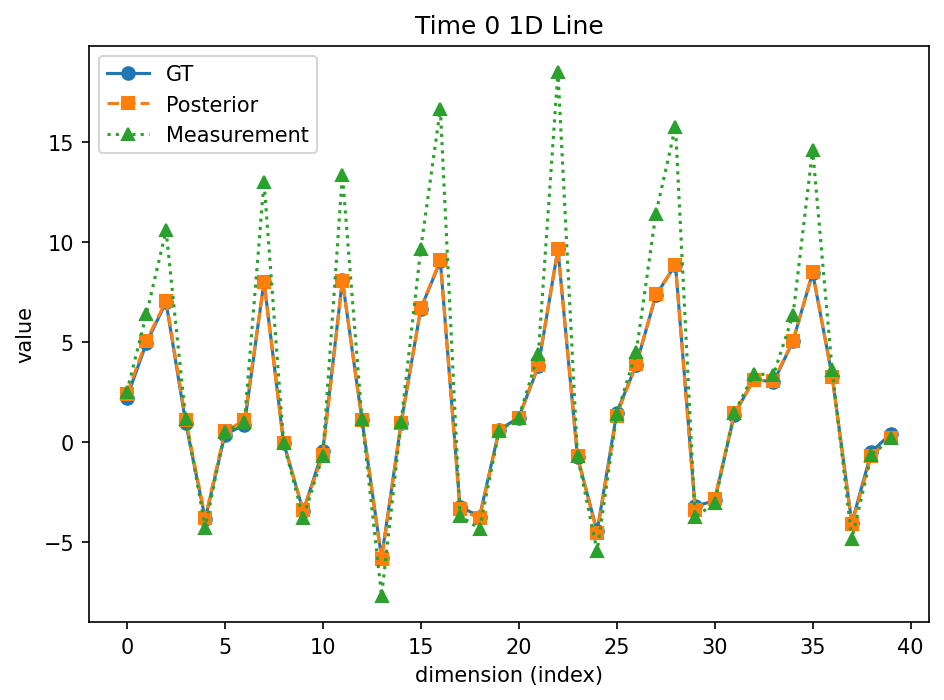

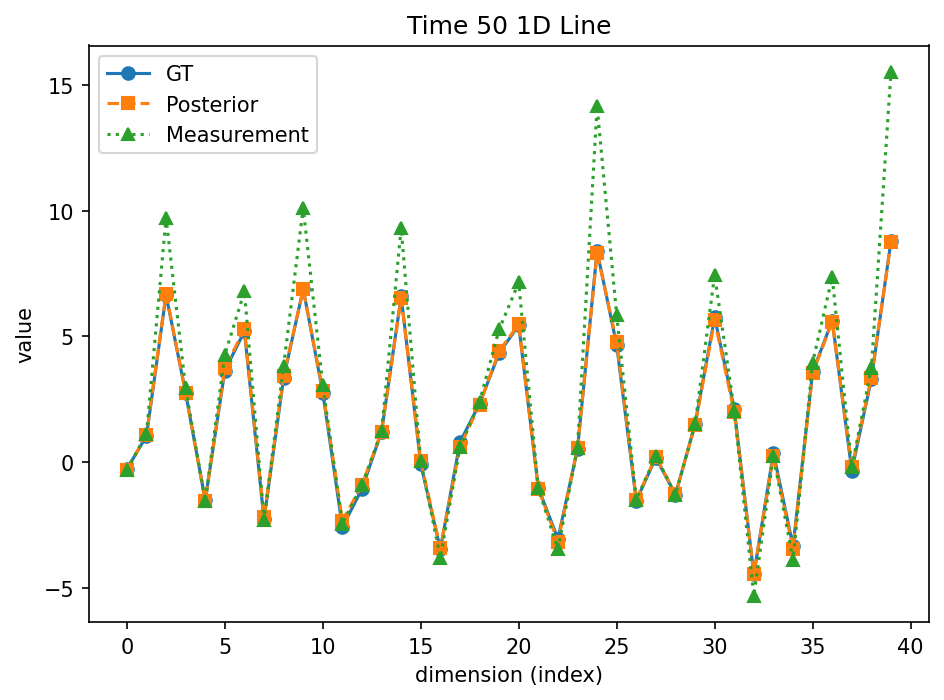

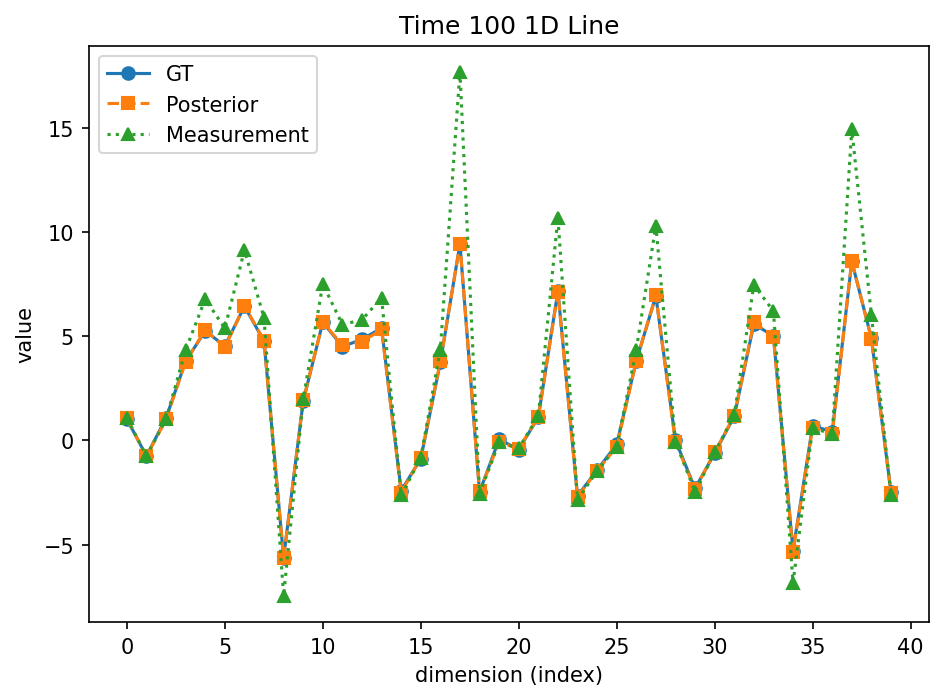

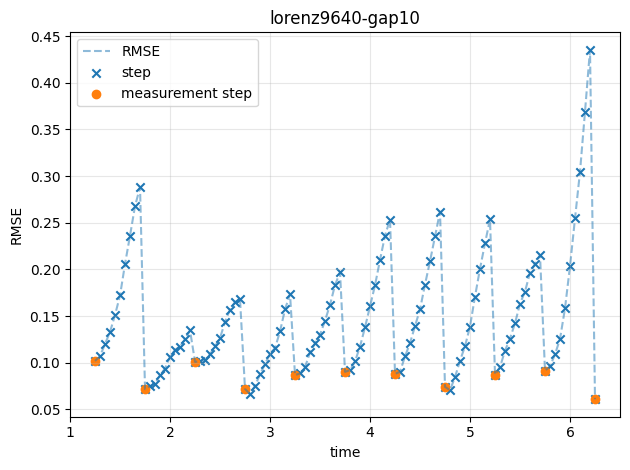

In [7]:
T = len(total_step)
for name in ["total.png", "total_0_variable.png", f"total_{T // 2}_variable.png", f"total_{T - 1}_variable.png"]:
    display(Image(filename=f"{OUT}/{name}"))
display(Image(filename=glob.glob(f"{OUT}/RMSE_mean*.png")[0]))